<a href="https://colab.research.google.com/github/Euphrasia03/Assignment/blob/main/LAB_1_Classificatiom_and_Prediction_(104073).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **LAB 1: Classificatiom and Prediction (104073)**

In [64]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Load and Prepare the Data

In [65]:
iris_data = load_iris()
X = pd.DataFrame(iris_data.data, columns=iris_data.feature_names)
y = pd.Series(iris_data.target, name="Target")

display(X.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


# 2. Train/ Test Split
Splitting the data so we can evaluate our model on unseen data.

In [66]:
X_train, X_test, y_train, y_test = train_test_split (X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Updated Training set shape: {X_train.shape[0]}")
print(f"Updated Test set shape: {X_test.shape[0]}\n")

Updated Training set shape: 120
Updated Test set shape: 30



# 3. Train the Classification Model
We will use a Random Forest Classifier

In [67]:
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

# 4. Make Prediction & Evaluate
Compare the predicted labels to the actual labels in the test set.

Accuracy: 0.9000 

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



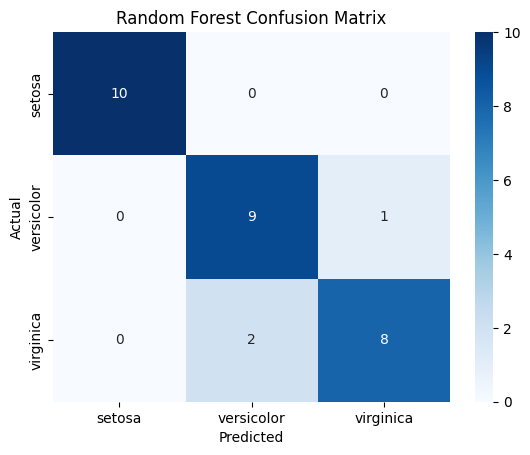

In [74]:
y_pred = clf.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f} \n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=iris_data.target_names))

# Plot Confusion Matrix
cn = confusion_matrix(y_test, y_pred)
sns.heatmap(cn, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris_data.target_names, yticklabels=iris_data.target_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()

# 5. Train and Evaluate Logistic Regression

In [69]:
log_reg = LogisticRegression(max_iter=200, random_state=42)
log_reg.fit(X_train, y_train)


LogisticRegression(max_iter=200, random_state=42)

Accuracy: 0.9667 

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



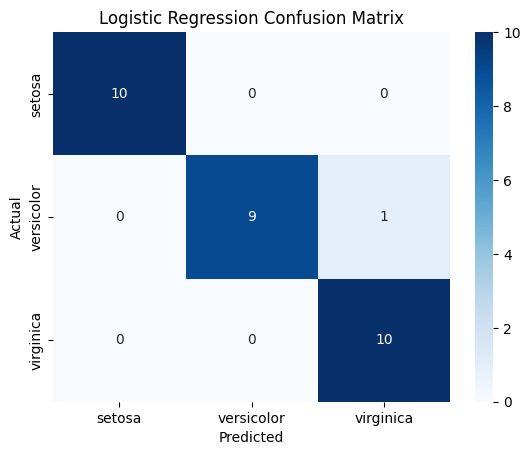

In [70]:
y_pred_lr = log_reg.predict(X_test)

# Evaluation
y_pred_lr = log_reg.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.4f} \n")
print("Classification Report:")
print(classification_report(y_test, y_pred_lr, target_names=iris_data.target_names))

# Plot Confusion Matrix
cn_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cn_lr, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris_data.target_names, yticklabels=iris_data.target_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [71]:
# Direct Accuracy Comparison
rf_acc = accuracy_score(y_test, y_pred)
lr_acc = accuracy_score(y_test, y_pred_lr)

print("--- Model Comparison ---")
print(f"Random Forest Accuracy:       {rf_acc:.4f}")
print(f"Logistic Regression Accuracy: {lr_acc:.4f}")

--- Model Comparison ---
Random Forest Accuracy:       0.9000
Logistic Regression Accuracy: 0.9667


# 6. Lab Deliverables and Analysis

1. Confusion Matrix Analysis:

What is the exact number of False Positives and False Negatives shown in your Random Forest confusion matrix?

Versicolor for Positive Class
*   False Positive: 2
*   False Negative: 1

Virginica for Positive Class
*   False Positive: 1
*   False Negative: 2

How do these numbers change in the confusion matrix for your chosen model?
*   For Logistic Regression, false positives went from 2 to 0 and false negatives went from 1 to 0.

2. Model Performance:

Based on the accuracy and the classification reports, which model performed better overall?

*   Random Forest had accuracy 90.00% and Logistic Regression had 96.67%. Logistic Regression performed better overall because it is more accurate.


